In [1]:
import pandas as pd
import numpy as np
import re
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../data/IMDB Dataset.csv')
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# Dataset shape
print("Dataset shape:", df.shape)

# Class distribution
print(df['sentiment'].value_counts())

Dataset shape: (50000, 2)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


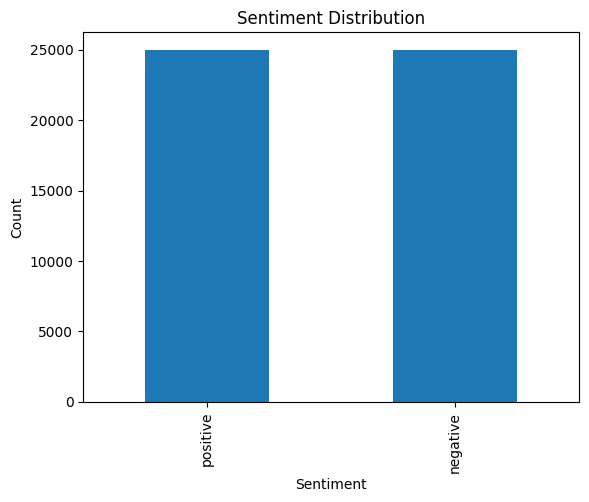

In [4]:
import matplotlib.pyplot as plt

df['sentiment'].value_counts().plot(kind='bar')
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

In [5]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    
    # remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    
    # remove special characters
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    
    words = text.split()
    
    # remove stopwords
    words = [w for w in words if w not in stop_words]
    
    return " ".join(words)

df['clean_review'] = df['review'].apply(clean_text)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\vpahu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [6]:
df['sentiment'] = df['sentiment'].map({'positive':1, 'negative':0})

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_review'],
    df['sentiment'],
    test_size=0.2,
    random_state=42
)


In [8]:
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer(max_features=5000)

X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [10]:
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
y_pred_nb = nb.predict(X_test_tfidf)

In [11]:
lr = LogisticRegression(max_iter=200)
lr.fit(X_train_tfidf, y_train)
y_pred_lr = lr.predict(X_test_tfidf)

In [12]:
svm = LinearSVC()
svm.fit(X_train_tfidf, y_train)
y_pred_svm = svm.predict(X_test_tfidf)

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

def evaluate_full(name, y_test, y_pred):
    print(f"\n{name}")
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1 Score:", f1)
    
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

In [14]:
evaluate_full("Naive Bayes", y_test, y_pred_nb)
evaluate_full("Logistic Regression", y_test, y_pred_lr)
evaluate_full("SVM", y_test, y_pred_svm)


Naive Bayes
Accuracy: 0.8553
Precision: 0.8536825521859
Recall: 0.8602897400277832
F1 Score: 0.8569734110902442
Confusion Matrix:
 [[4218  743]
 [ 704 4335]]

Logistic Regression
Accuracy: 0.8915
Precision: 0.8818076477404403
Recall: 0.9061321690811669
F1 Score: 0.8938044435744348
Confusion Matrix:
 [[4349  612]
 [ 473 4566]]

SVM
Accuracy: 0.8816
Precision: 0.8755113968439509
Recall: 0.8918436197658266
F1 Score: 0.8836020448289422
Confusion Matrix:
 [[4322  639]
 [ 545 4494]]


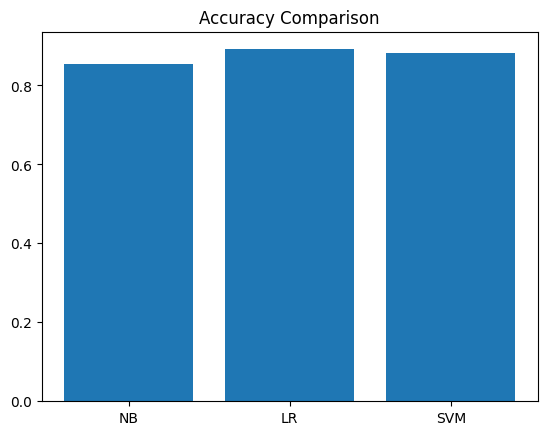

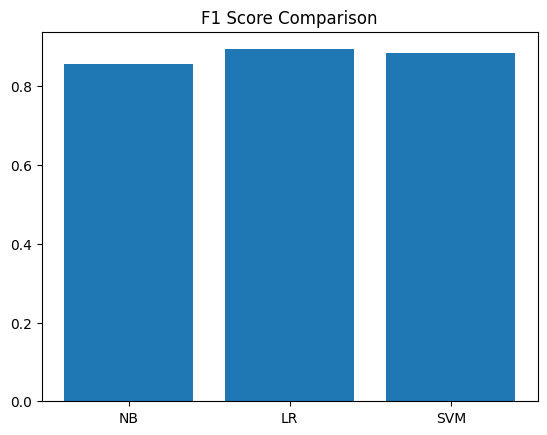

In [15]:
models = ['NB', 'LR', 'SVM']
accuracy = [
    accuracy_score(y_test, y_pred_nb),
    accuracy_score(y_test, y_pred_lr),
    accuracy_score(y_test, y_pred_svm)
]

f1_scores = [
    f1_score(y_test, y_pred_nb),
    f1_score(y_test, y_pred_lr),
    f1_score(y_test, y_pred_svm)
]

plt.figure()
plt.bar(models, accuracy)
plt.title("Accuracy Comparison")
plt.show()

plt.figure()
plt.bar(models, f1_scores)
plt.title("F1 Score Comparison")
plt.show()

In [16]:
# Example prediction
sample = ["This movie was absolutely amazing and fantastic"]
sample_clean = clean_text(sample[0])

sample_vec = tfidf.transform([sample_clean])
prediction = svm.predict(sample_vec)

print("Prediction:", "Positive" if prediction[0]==1 else "Negative")

Prediction: Positive


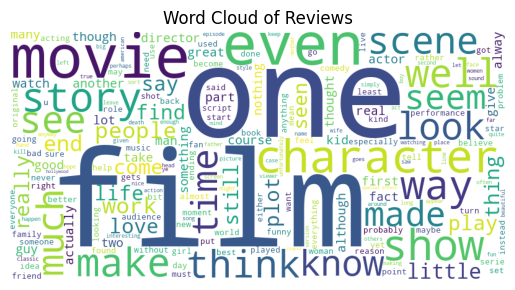

In [18]:
from wordcloud import WordCloud

# Combine all reviews
all_text = " ".join(df['clean_review'])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text)

plt.figure()
plt.imshow(wordcloud)
plt.axis('off')
plt.title("Word Cloud of Reviews")
plt.show()

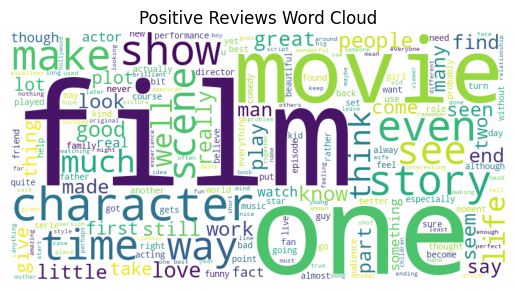

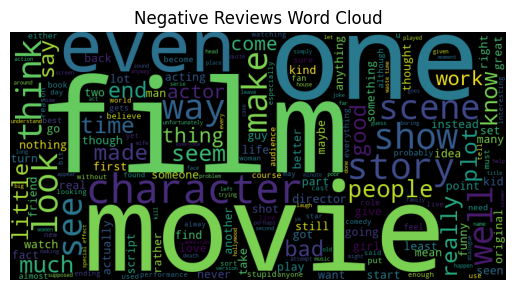

In [19]:
positive_text = " ".join(df[df['sentiment']==1]['clean_review'])
negative_text = " ".join(df[df['sentiment']==0]['clean_review'])

wc_pos = WordCloud(width=800, height=400, background_color='white').generate(positive_text)
wc_neg = WordCloud(width=800, height=400, background_color='black').generate(negative_text)

plt.figure()
plt.imshow(wc_pos)
plt.axis('off')
plt.title("Positive Reviews Word Cloud")
plt.show()

plt.figure()
plt.imshow(wc_neg)
plt.axis('off')
plt.title("Negative Reviews Word Cloud")
plt.show()

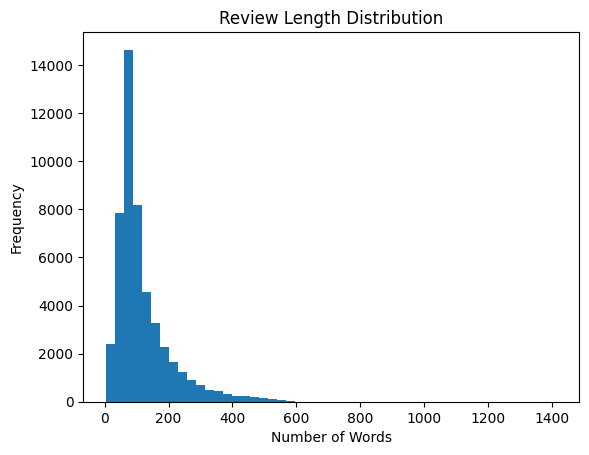

In [20]:
df['review_length'] = df['clean_review'].apply(lambda x: len(x.split()))

plt.figure()
plt.hist(df['review_length'], bins=50)
plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [21]:
# Create review length column
df['review_length'] = df['clean_review'].apply(lambda x: len(x.split()))

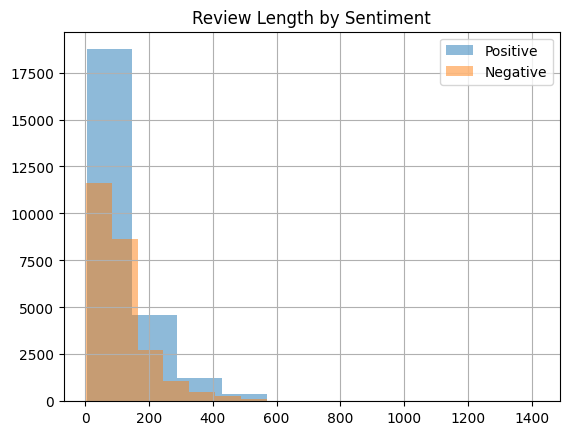

In [22]:
plt.figure()
df[df['sentiment']==1]['review_length'].hist(alpha=0.5, label='Positive')
df[df['sentiment']==0]['review_length'].hist(alpha=0.5, label='Negative')

plt.legend()
plt.title("Review Length by Sentiment")
plt.show()

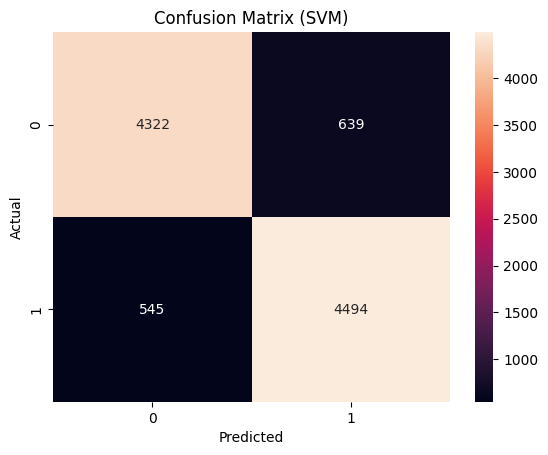

In [23]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_svm)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix (SVM)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [24]:
feature_names = tfidf.get_feature_names_out()

coefficients = lr.coef_[0]

top_positive = sorted(zip(coefficients, feature_names), reverse=True)[:10]
top_negative = sorted(zip(coefficients, feature_names))[:10]

print("Top Positive Words:")
for coef, word in top_positive:
    print(word)

print("\nTop Negative Words:")
for coef, word in top_negative:
    print(word)

Top Positive Words:
great
excellent
perfect
wonderful
amazing
brilliant
best
hilarious
loved
favorite

Top Negative Words:
worst
waste
awful
bad
boring
terrible
poor
dull
nothing
poorly


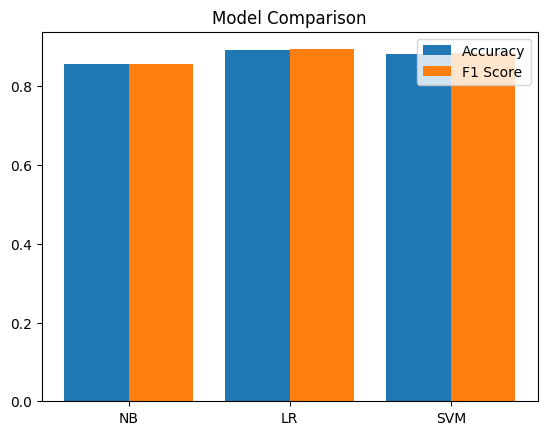

In [25]:
import numpy as np

x = np.arange(len(models))

plt.figure()
plt.bar(x - 0.2, accuracy, 0.4, label='Accuracy')
plt.bar(x + 0.2, f1_scores, 0.4, label='F1 Score')

plt.xticks(x, models)
plt.legend()
plt.title("Model Comparison")
plt.show()

In [26]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10]
}

grid_lr = GridSearchCV(LogisticRegression(max_iter=200), param_grid, cv=3)
grid_lr.fit(X_train_tfidf, y_train)

best_lr = grid_lr.best_estimator_
y_pred_best_lr = best_lr.predict(X_test_tfidf)

print("Best Params:", grid_lr.best_params_)

Best Params: {'C': 1}


In [27]:
param_grid = {
    'C': [0.1, 1, 10]
}

grid_svm = GridSearchCV(LinearSVC(), param_grid, cv=3)
grid_svm.fit(X_train_tfidf, y_train)

best_svm = grid_svm.best_estimator_
y_pred_best_svm = best_svm.predict(X_test_tfidf)

print("Best Params:", grid_svm.best_params_)

Best Params: {'C': 0.1}


In [28]:
evaluate_full("Tuned Logistic Regression", y_test, y_pred_best_lr)
evaluate_full("Tuned SVM", y_test, y_pred_best_svm)


Tuned Logistic Regression
Accuracy: 0.8915
Precision: 0.8818076477404403
Recall: 0.9061321690811669
F1 Score: 0.8938044435744348
Confusion Matrix:
 [[4349  612]
 [ 473 4566]]

Tuned SVM
Accuracy: 0.8919
Precision: 0.8810165575664228
Recall: 0.9081166898194086
F1 Score: 0.8943613798495065
Confusion Matrix:
 [[4343  618]
 [ 463 4576]]


In [29]:
import pandas as pd

results = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression', 'SVM', 'Tuned LR', 'Tuned SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_best_lr),
        accuracy_score(y_test, y_pred_best_svm)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_best_lr),
        f1_score(y_test, y_pred_best_svm)
    ]
})

results

,Model,Accuracy,F1 Score
0,Naive Bayes,0.8553,0.856973
1,Logistic Regression,0.8915,0.893804
2,SVM,0.8816,0.883602
3,Tuned LR,0.8915,0.893804
4,Tuned SVM,0.8919,0.894361


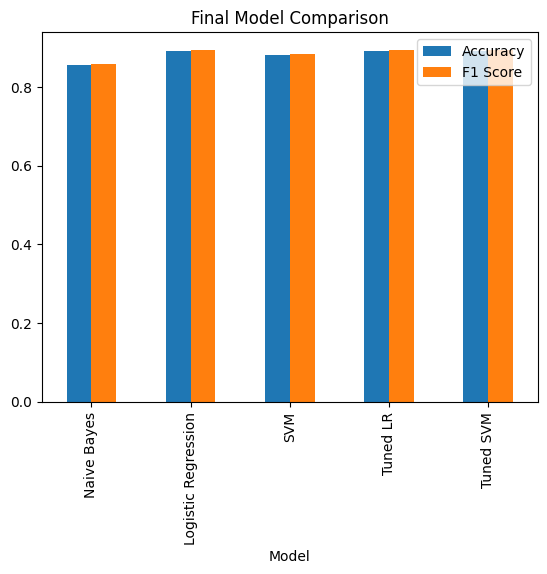

In [30]:
results.plot(x='Model', y=['Accuracy', 'F1 Score'], kind='bar')
plt.title("Final Model Comparison")
plt.show()